In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Timoteo\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np 

In [3]:
amazon_uk_prices = pd.read_csv(r"C:\Users\Timoteo\OneDrive\Documents\Iron_Hack\Week_2\Labs\D4\lab-eda-univariate\amz_uk_price_prediction_dataset.csv")

In [4]:
amazon_uk_prices.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
amazon_uk_prices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [6]:
amazon_uk_prices.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [7]:
cat = amazon_uk_prices.select_dtypes(exclude="number")
num = amazon_uk_prices.select_dtypes(include="number")

In [9]:
cat.columns


Index(['asin', 'title', 'isBestSeller', 'category'], dtype='object')

In [10]:
num.columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    - Are there categories where being a best-seller is more prevalent? 
            *Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [ ]:
# Create a crosstab between the product `category` and the `isBestSeller` status
crosstab_cat_ibs= pd.crosstab(cat['category'], cat['isBestSeller'])
crosstab_cat_ibs

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [13]:
# Are there categories where being a best-seller is more prevalent? 
crosstab_percent = pd.crosstab(amazon_uk_prices['category'], amazon_uk_prices['isBestSeller'], normalize='index') * 100
crosstab_percent.round(2)

## Categories where the percentage of True is much higher than others are the ones where being a best-seller is more prevalent.

isBestSeller,False,True
category,,
3D Printers,99.60,0.40
3D Printing & Scanning,99.95,0.05
Abrasive & Finishing Products,98.00,2.00
Action Cameras,99.94,0.06
Adapters,98.82,1.18
...,...,...
Wind Instruments,97.20,2.80
Window Treatments,97.91,2.09
Women,98.80,1.20


In [14]:
# Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
from scipy.stats import chi2_contingency

chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_cat_ibs)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [15]:
# Compute Cramér's V to understand the strength of association between best-seller status and category.
from scipy.stats.contingency import association
association(crosstab_cat_ibs, method="cramer")

0.1222829439760564

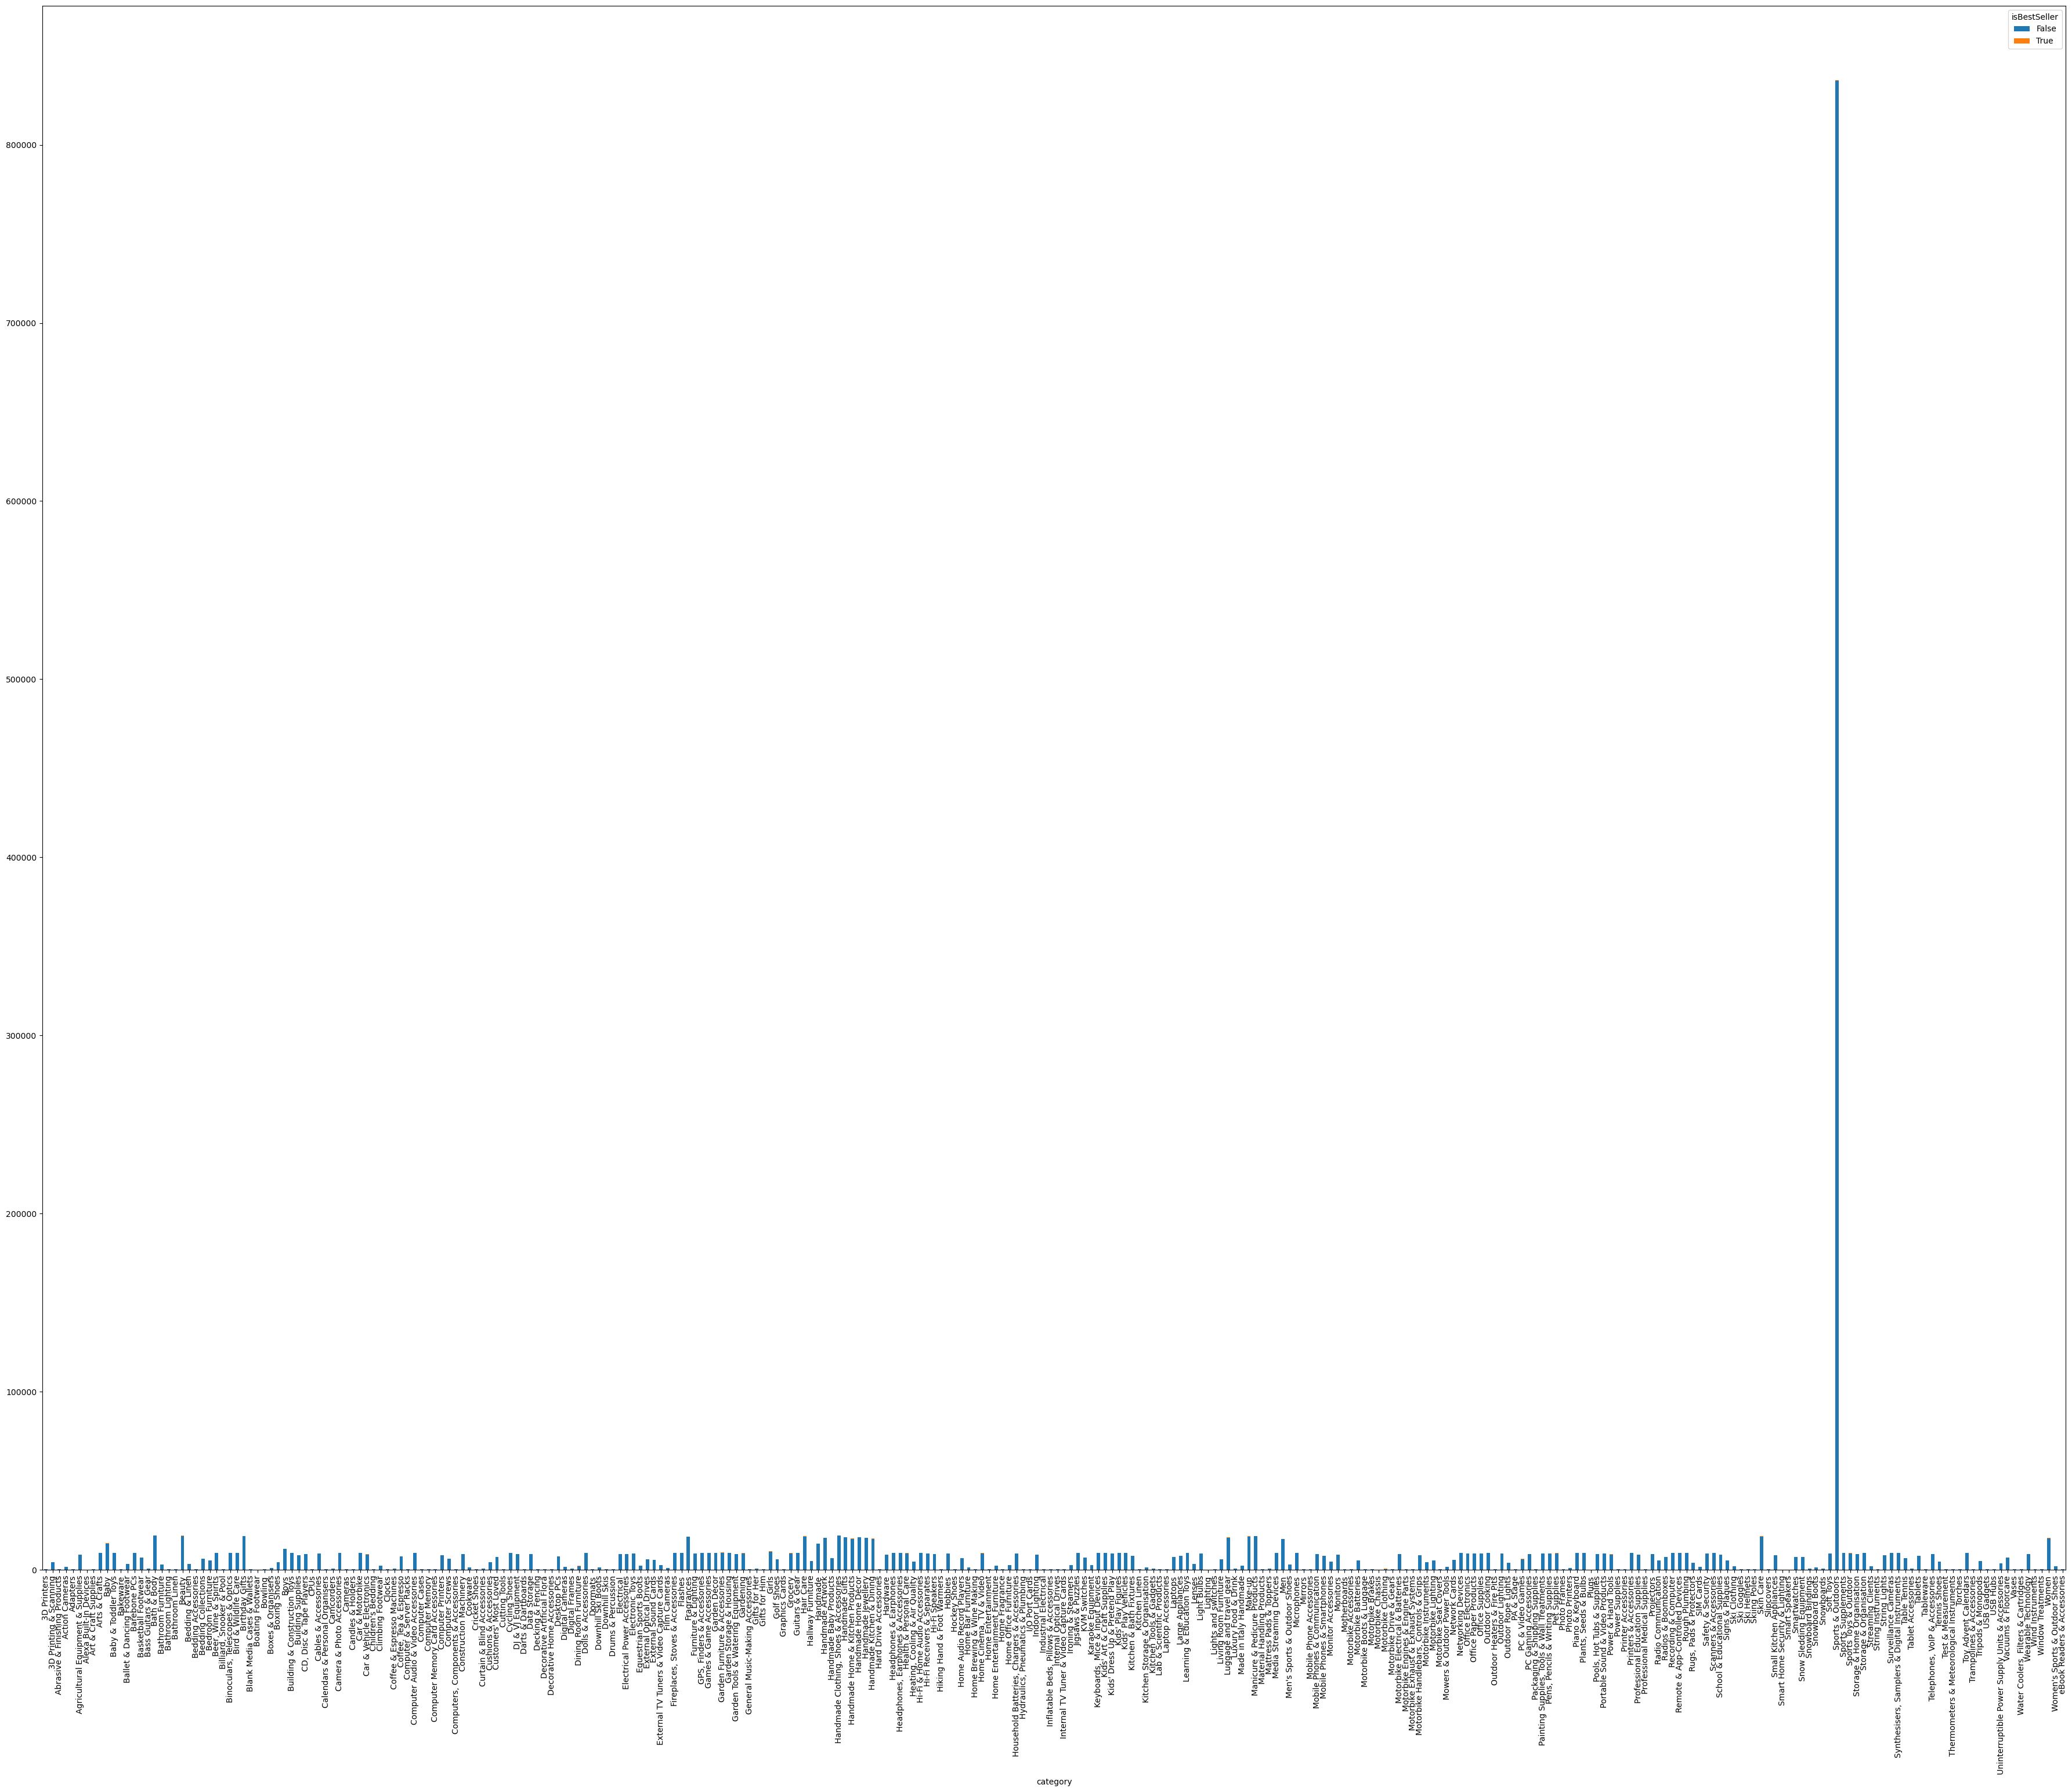

In [25]:
crosstab_cat_ibs.plot(kind='bar', stacked=True, figsize=(45,35))
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [27]:
# Preliminary Step: Remove outliers in product prices
amazon_uk_prices['price'] = pd.to_numeric(amazon_uk_prices['price'], errors='coerce')
amazon_uk_prices = amazon_uk_prices.dropna(subset=['price'])
def tukeys_test_outliers(data,column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    filtered_data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]
    return filtered_data

In [29]:
df_no_outliers = tukeys_test_outliers(amazon_uk_prices, 'price')
print(f"After removing outliers: {df_no_outliers.shape}")

After removing outliers: (2115963, 9)


C:\Users\Timoteo\AppData\Local\Temp\ipykernel_43200\3298881243.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='category', y='price', palette="coolwarm");


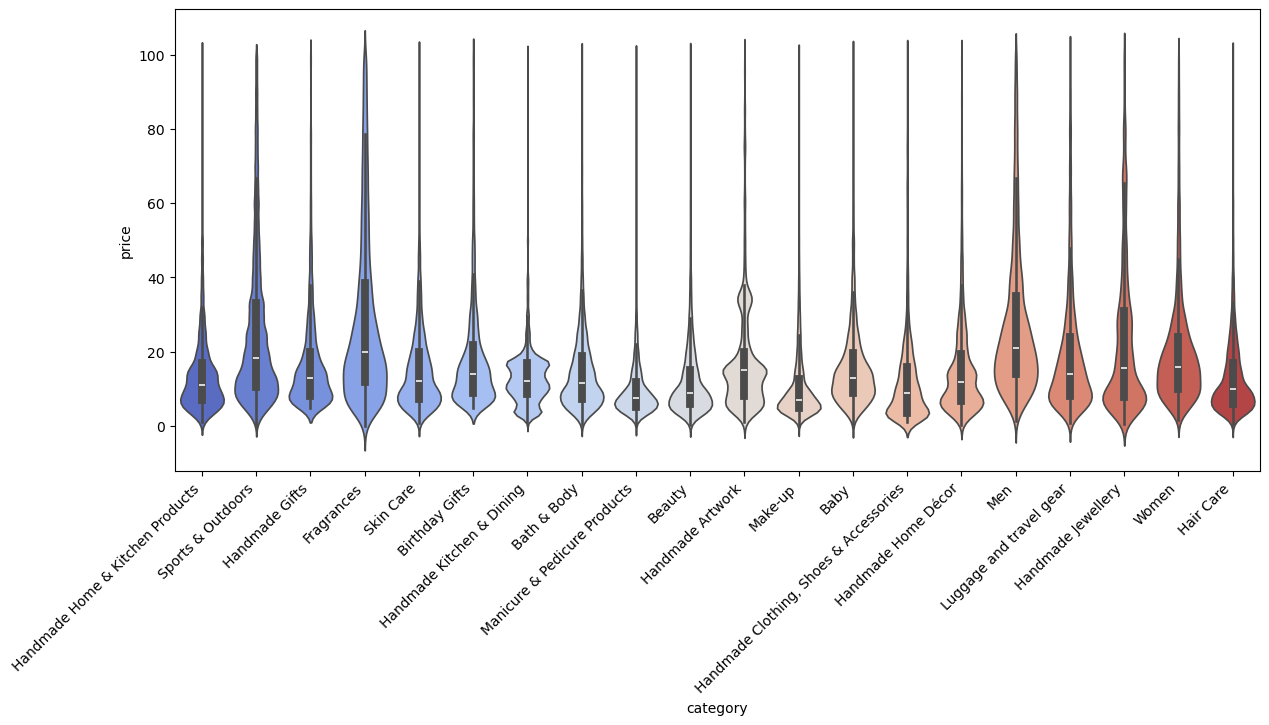

In [66]:
# Use a violin plot to visualize the distribution of `price` across different product `categories`. 
# Filter out the top 20 categories based on count for better visualization.

top20_cat = df_no_outliers['category'].value_counts().head(20).index

df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_cat)]

plt.figure(figsize=(14, 6))
sns.violinplot(data=df_top20, x='category', y='price', palette="coolwarm");
plt.xticks(rotation=45, ha="right")
plt.show()

In [67]:
# Which product category commands the highest average price? Don't filter here by top categories.
median_prod = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
highest_cat = median_prod.index[0]
highest_price = median_prod.iloc[0]
print(highest_cat)
print(highest_price)

Desktop PCs
74.0


C:\Users\Timoteo\AppData\Local\Temp\ipykernel_43200\1612268150.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_prices_top10.index, y=avg_prices_top10.values, palette="coolwarm", errorbar=None)


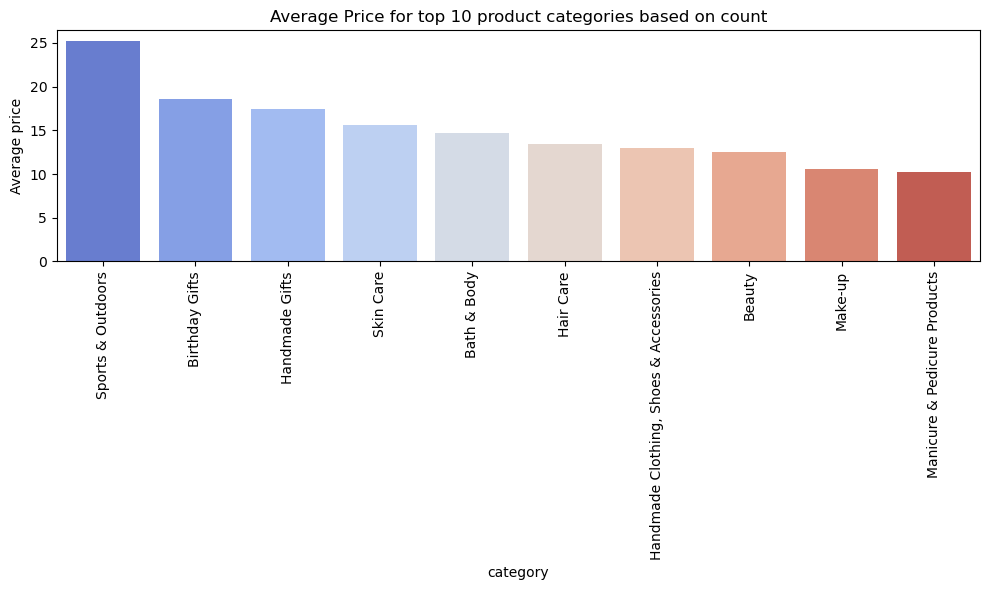

In [79]:
# Create a bar chart comparing the average price of products for the top 10 product categories (based on count)
top_categories_10 = df_no_outliers['category'].value_counts().nlargest(10).index
df_top_10 = df_no_outliers[df_no_outliers['category'].isin(top_categories_10)]

avg_prices_top10 = df_top_10.groupby('category')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=avg_prices_top10.index, y=avg_prices_top10.values, palette="coolwarm", errorbar=None)
plt.xticks(rotation=90)
plt.ylabel("Average price")
plt.title("Average Price for top 10 product categories based on count")
plt.tight_layout()
plt.show()

In [69]:
# Which product category commands the highest average price? Don't filter here by top categories
mean_prod = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)
highest_cat2 = mean_prod.index[0]
highest_price2 = mean_prod.iloc[0]
print(highest_cat2)
print(highest_price2)

Motherboards
68.77243243243242


C:\Users\Timoteo\AppData\Local\Temp\ipykernel_43200\420331224.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x="category", y="stars", palette="flare", legend=True)


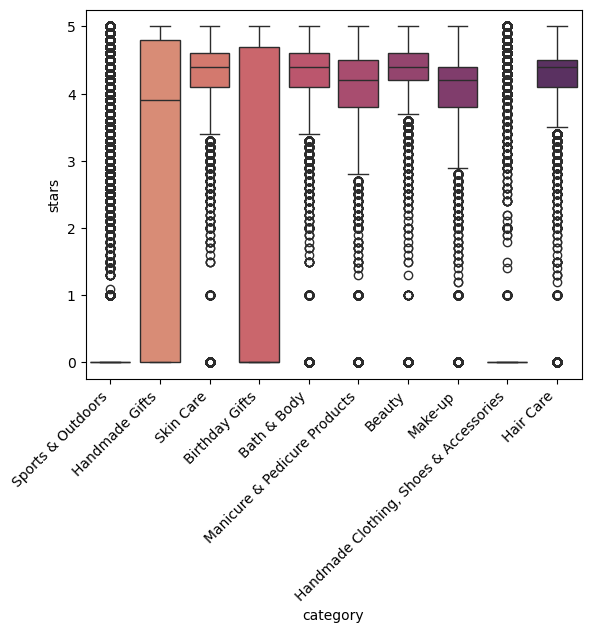

In [70]:
# Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
top10_cat = df_no_outliers['category'].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_cat)]

sns.boxplot(data=df_top10, x="category", y="stars", palette="flare", legend=True)
plt.xticks(rotation=45, ha="right")
plt.show()

In [80]:
# Which category tends to receive the highest median rating from customers? Don't filter here by top categories.
median_rate = df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False)
highest_cat_rate = median_rate.index[0]
highest_rating = median_rate.iloc[0]
print(highest_cat_rate)
print(highest_rating)

Computer Memory
4.7


### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 


In [84]:
# Calculate the correlation coefficient between `price` and `stars`.
correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])
correlation

np.float64(-0.07767299878181323)

In [85]:
# Is there a significant correlation between product price and its rating?
correlation2 = df_no_outliers['price'].corr(df_no_outliers['stars'], method='spearman')
correlation2

np.float64(-0.06679697280768307)

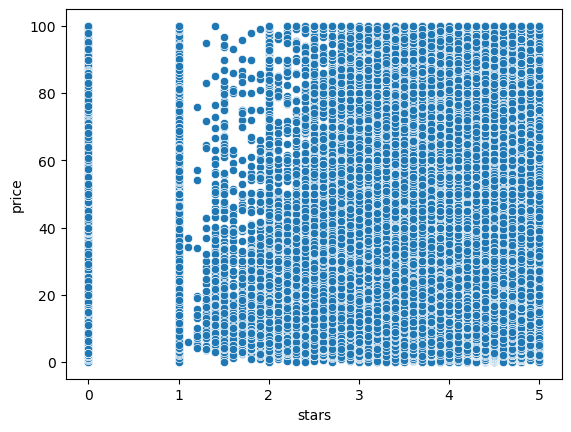

In [86]:
# Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
sns.scatterplot(data=df_no_outliers, x='stars', y='price')
plt.show()

In [88]:
# Use a correlation heatmap to visualize correlations between all numerical variables.
num.corr()


,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.031696,0.019994,0.008273,0.016336
stars,0.031696,1.000000,0.085808,-0.124907,0.112536
reviews,0.019994,0.085808,1.000000,-0.013171,0.104043
price,0.008273,-0.124907,-0.013171,1.000000,-0.023439
boughtInLastMonth,0.016336,0.112536,0.104043,-0.023439,1.000000


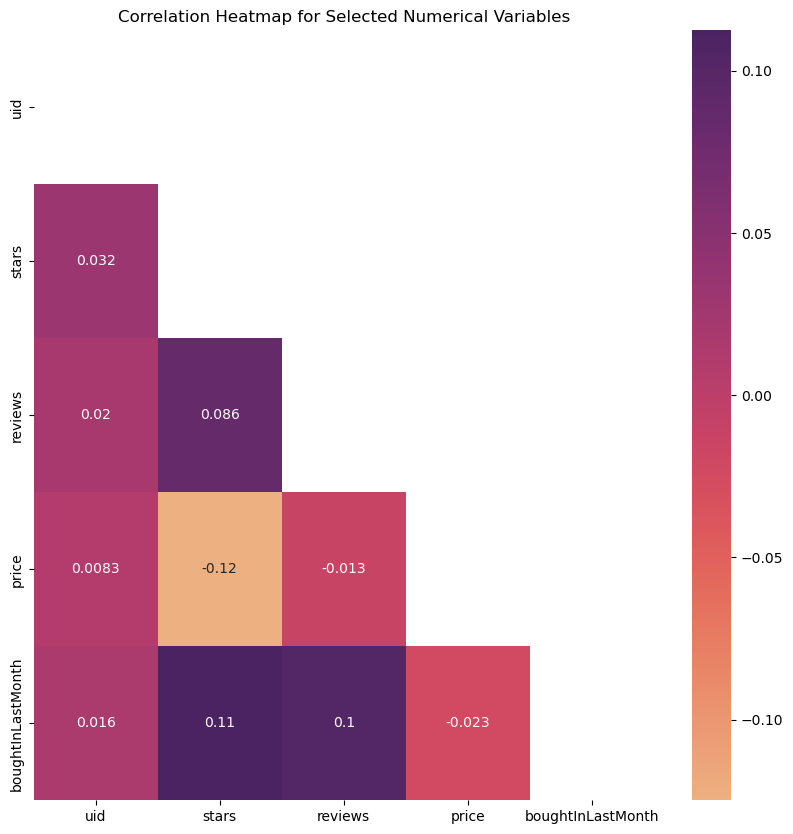

In [64]:
correlation_matrix = num.corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(10, 10))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="flare")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

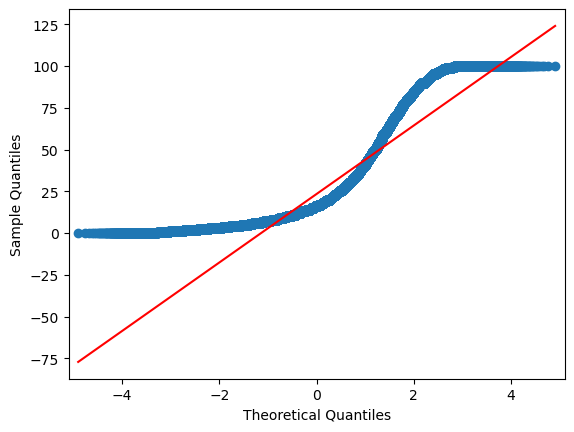

In [74]:
# Examine if product prices typically follow a normal distribution using a QQ plot

import statsmodels.api as sm

sm.qqplot(df_no_outliers['price'], line='s');
plt.show()